# DataCamp's Investigating Movies Project
**Netflix!** What started in 1997 as a DVD rental service has since exploded into one of the largest entertainment and media companies.

Given the large number of movies and series available on the platform, it is a perfect opportunity to flex your exploratory data analysis skills and dive into the entertainment industry.

You work for a production company that specializes in nostalgic styles. You want to do some research on movies released in the 1990's. You'll delve into Netflix data and perform exploratory data analysis to better understand this awesome movie decade!

You have been supplied with the dataset `netflix_data.csv`, along with the following table detailing the column names and descriptions. Feel free to experiment further after submitting!

### The data

#### `netflix_data.csv`

| Column | Description |
| :--- | :--- |
| **show_id** | The ID of the show |
| **type** | Type of show |
| **title** | Title of the show |
| **director** | Director of the show |
| **cast** | Cast of the show |
| **country** | Country of origin |
| **date_added** | Date added to Netflix |
| **release_year** | Year of Netflix release |
| **duration** | Duration of the show in minutes |
| **description** | Description of the show |
| **genre** | Show genre |

In [73]:
# Importing relevant libraries
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_data.csv")
df.head(20)

,show_id,type,title,director,cast,country,date_added,release_year,duration,description,genre
0,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,93,After a devastating earthquake hits Mexico Cit...,Dramas
1,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,78,"When an army recruit is found dead, his fellow...",Horror Movies
2,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,80,"In a postapocalyptic world, rag-doll robots hi...",Action
3,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,123,A brilliant group of students become card-coun...,Dramas
4,s6,TV Show,46,Serdar Akar,"Erdal Beşikçioğlu, Yasemin Allen, Melis Birkan...",Turkey,"July 1, 2017",2016,1,A genetics professor experiments with a treatm...,International TV
5,s7,Movie,122,Yasir Al Yasiri,"Amina Khalil, Ahmed Dawood, Tarek Lotfy, Ahmed...",Egypt,"June 1, 2020",2019,95,"After an awful accident, a couple admitted to ...",Horror Movies
6,s8,Movie,187,Kevin Reynolds,"Samuel L. Jackson, John Heard, Kelly Rowan, Cl...",United States,"November 1, 2019",1997,119,After one of his high school students attacks ...,Dramas
7,s9,Movie,706,Shravan Kumar,"Divya Dutta, Atul Kulkarni, Mohan Agashe, Anup...",India,"April 1, 2019",2019,118,"When a doctor goes missing, his psychiatrist w...",Horror Movies
8,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,"December 15, 2017",2008,143,An architect and his wife move into a castle t...,Horror Movies
9,s11,Movie,1922,Zak Hilditch,"Thomas Jane, Molly Parker, Dylan Schmid, Kaitl...",United States,"October 20, 2017",2017,103,A farmer pens a confession admitting to his wi...,Dramas


In [74]:
# Having an overview about this netflix_data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4812 entries, 0 to 4811
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       4812 non-null   str  
 1   type          4812 non-null   str  
 2   title         4812 non-null   str  
 3   director      4812 non-null   str  
 4   cast          4812 non-null   str  
 5   country       4812 non-null   str  
 6   date_added    4812 non-null   str  
 7   release_year  4812 non-null   int64
 8   duration      4812 non-null   int64
 9   description   4812 non-null   str  
 10  genre         4812 non-null   str  
dtypes: int64(2), str(9)
memory usage: 413.7 KB


There are 11 columns, there are no null values and target columns are in right format

In [75]:
# Check for duplicate values/entries
df.duplicated().sum()

np.int64(0)

The DataFrame has no duplicated values

# Subsetting the DataFrame

In [76]:
# Check occurences of unique values
df["release_year"].value_counts()

release_year
2017    646
2018    624
2016    562
2019    488
2020    379
       ... 
1964      1
1942      1
1947      1
1944      1
1959      1
Name: count, Length: 71, dtype: int64

In [77]:
# Subsetting the DataFrame to isolate movies released from 1990 to 1999
subset = df.loc[(df["type"] == "Movie") & (df["release_year"].between(1990, 1999))]

subset["release_year"].value_counts()


release_year
1997    26
1998    26
1999    26
1993    16
1995    16
1992    16
1996    15
1990    14
1991    14
1994    14
Name: count, dtype: int64

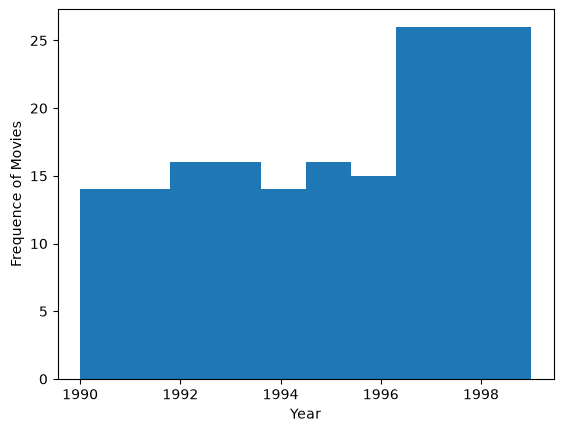

In [78]:
# Create a histogram to visualize frequence of movies in the 1990s
plt.hist(subset["release_year"])
plt.xlabel("Year")
plt.ylabel("Frequence of Movies")
plt.show()

Netflix featured a higher proportion of movies premiered in the late 1990s than those released in the early and mid 1990s

# Task 1
What was the most frequent movie duration in the 1990s? Save an approximate answer as an integer called duration (use 1990 as the decade's start year).

In [79]:
movie_count = df.loc[df["type"] == "Movie"]

In [80]:
# Using the "mode" to build statistic function to deduce the most frequent movies duration in the 1990s
duration_90s = df.loc[
    (df["type"] == "Movie") & (df["release_year"].between(1990, 1999)), "duration"
]
duration = duration_90s.mode()
duration

0    94
Name: duration, dtype: int64

The most frequent movie duration in 1990s is 94 mintues.

In [81]:
# Confirming the data type of variable name "duration"
duration.dtype

dtype('int64')

# Task 2
A movie is considered short if it is less than 90 minutes. Count the number of short action movies released in the 1990s and save this integer as short_movie_count.

In [82]:
# Checking out the different genre of movies released in 1990s
subset['genre'].value_counts()

genre
Action            48
Dramas            44
Comedies          40
Children          15
Classic Movies    15
Stand-Up           8
Thrillers          5
Horror Movies      4
Documentaries      2
Cult Movies        2
Name: count, dtype: int64

Text(0.5, 1.0, 'Genre of Movies Released in 1990s')

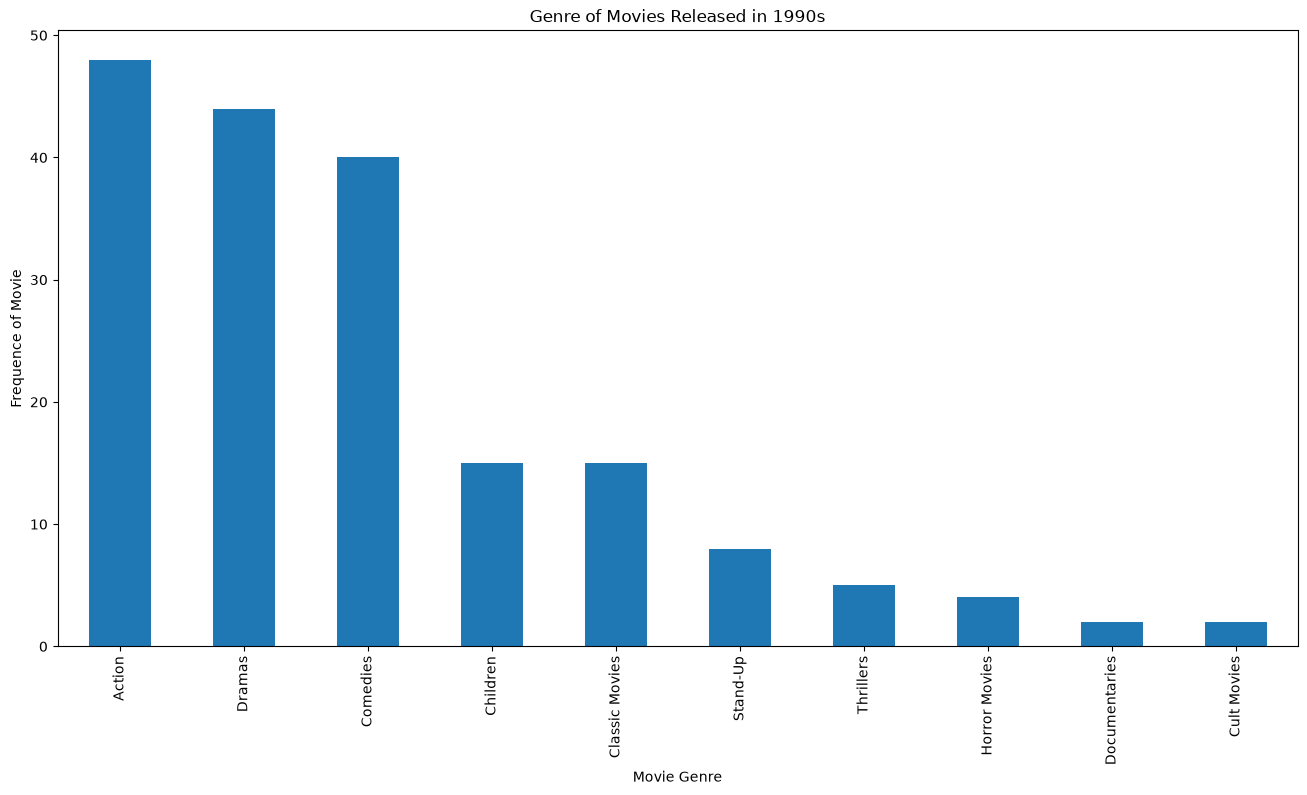

In [83]:
# Creating a bar plot to visulize the genre of movies released in 1990s
subset['genre'].value_counts().plot(kind='bar', figsize=(16,8))
plt.xlabel('Movie Genre')
plt.ylabel('Frequence of Movie')
plt.title('Genre of Movies Released in 1990s')

# Subsetting the short action movies with duration less than 90 minutes #

In [84]:
short_action_movie = (subset['genre']=='Action') & (subset['duration']<90)
short_action_movie

6       False
118     False
145     False
167     False
194     False
        ...  
4672    False
4689    False
4718    False
4746    False
4756    False
Length: 183, dtype: bool

In [85]:
# Obtaining the total count of short action movies with duration less than 90 mins
short_movie_count = short_action_movie.sum()
short_movie_count

np.int64(7)

Hence, there are 7 short action movies.